# Phase 2: causal claim reasoning

One DistilBERT reader, a small ML/DL comparison, reviewed candidate graphs, and checked Bayesian queries. This notebook displays saved measurements; it does not start training. The DL experiments use the documented local training subset, not the full Phase 1 training set.

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
from IPython.display import display, Image, Markdown
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "phase2.py").exists())
OUT = ROOT / "outputs" / "phase2"
def read(name):
    path = OUT / name
    if not path.exists() and path.name == "COMPLETE.json": path = path.with_name("TRAINING_RECORD.json")
    return json.loads(path.read_text())
assert read("SUCCESS.json")["complete"]
print("Results folder:", OUT.relative_to(ROOT))

Results folder: outputs/phase2


## 1. Reproducible data budget

Whole premise groups stay together. Development selects settings; test measures the final frozen protocol. Exact row IDs are retained in the manifest.

In [2]:
manifest = read("data_manifest.json")
for split, values in manifest["splits"].items():
    print(split, {k:v for k,v in values.items() if k != "docIds"})

dev {'max_pair_tokens': 848, 'max_windows': 2, 'multi_window_rows': 242, 'positive': 121, 'rows': 984, 'systems': 17}
test {'max_pair_tokens': 510, 'max_windows': 1, 'multi_window_rows': 0, 'positive': 180, 'rows': 1162, 'systems': 21}
train {'max_pair_tokens': 1696, 'max_windows': 4, 'multi_window_rows': 810, 'positive': 332, 'rows': 2100, 'systems': 25}


## 2. One reader, one decision

A short example is processed once. For long examples the same encoder reads consecutive premise windows, each paired with the complete hypothesis. Average the valid window representations, then make one document decision. Every original token is retained; this averaging is not full cross-window attention.

# Phase 2 results

Train subset: 2100 records in whole premise groups; dev 984; test 1162.
This is a local compute-budget experiment, not a full-205,734-row DL training run.

| Model | Dev macro F1 | Test macro F1 | Positive P | Positive R |
|---|---:|---:|---:|---:|
| Matched ML | 0.5788 | 0.5927 | 0.3431 | 0.2611 |
| Full-train ML (context only) | 0.6534 | 0.6357 | 0.3510 | 0.4778 |
| main | 0.6844 | 0.6726 | 0.3739 | 0.7333 |
| frozen | 0.5917 | 0.5679 | 0.3040 | 0.2111 |
| unweighted | 0.6510 | 0.6443 | 0.3408 | 0.6722 |
| Hybrid matched ML + DL | 0.6871 | 0.6718 | 0.3725 | 0.7389 |

Demo classifier selected on development data: Hybrid matched ML + DL.
Full-train ML is contextual only. Fair budget comparison uses Matched ML and the same DL training rows.
Graph scores measure entailed direct relations, with cycle removal evaluated separately.
Demo review uses an explicit finite-DAG constraint check on small systems; it is automated, not human approval.
CPDs in the numerical demo are supplied assumptions, not estimated from Corr2Cause.
Integration graph source: Hybrid matched ML + DL.
One seed (42); no claim of statistically established superiority or real-world causal discovery.


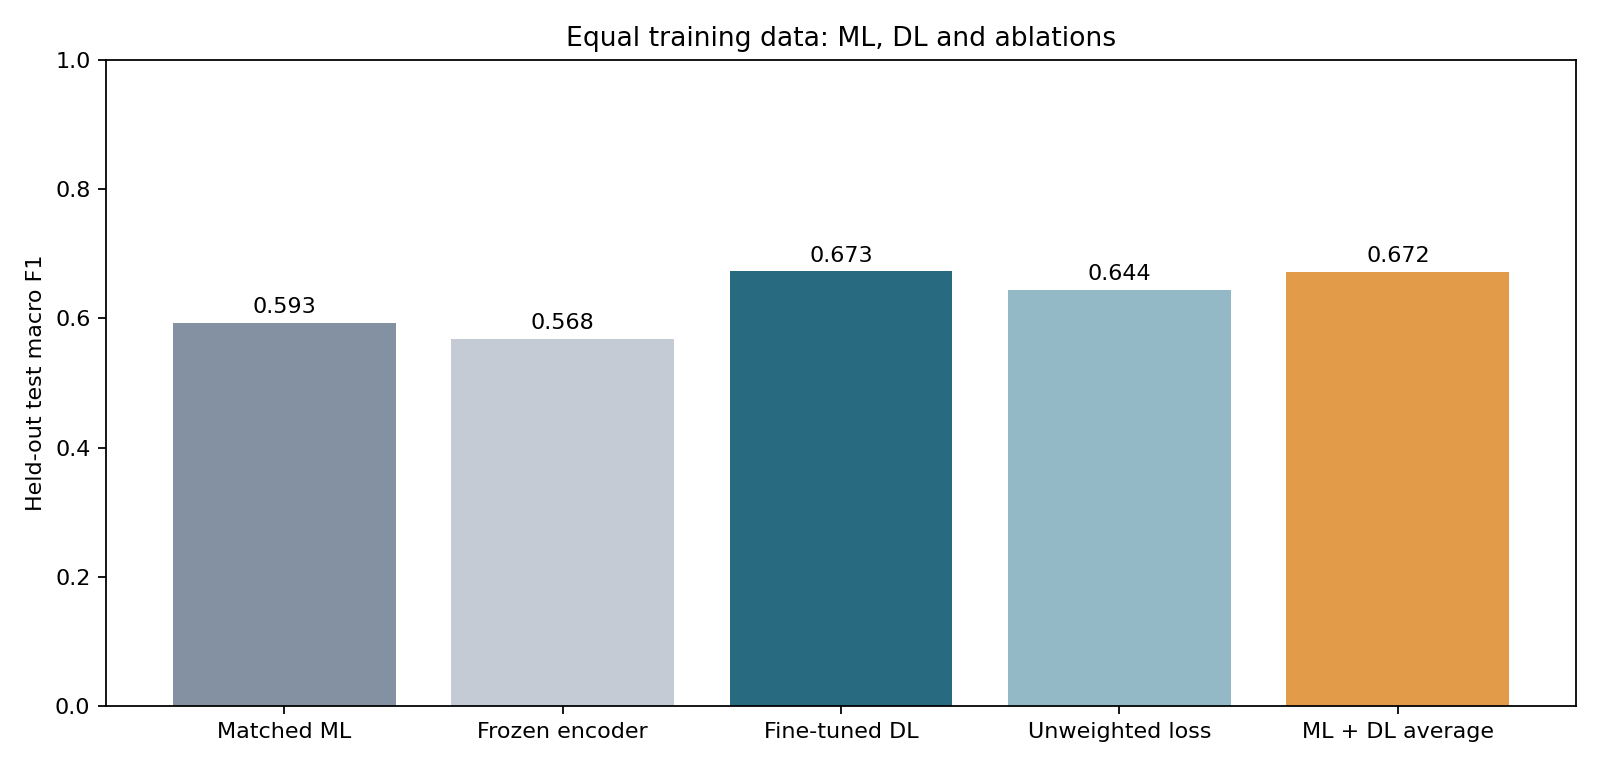

In [3]:
display(Markdown((OUT / "RESULTS.md").read_text()))
display(Image(filename=str(OUT / "classification.png")))

## 3. Ablations

Frozen encoder versus fine-tuning examines task adaptation. Weighted versus ordinary loss examines imbalance handling. The score average tests whether existing structural features complement text representations. A negative result is retained.

In [4]:
for experiment in ["frozen", "main", "unweighted"]:
    record = read(experiment + "/COMPLETE.json")
    print(experiment, "best:", record["best"], "epochs:", len(record["history"]))

frozen best: {'dev_macro_f1': 0.5916661551116622, 'elapsed_seconds': 279.0318069458008, 'epoch': 3, 'threshold': 0.7, 'train_loss': 0.6289582974982985} epochs: 3
main best: {'dev_macro_f1': 0.6844064183447123, 'elapsed_seconds': 821.9724569320679, 'epoch': 3, 'threshold': 0.44999999999999996, 'train_loss': 0.4554835173469924} epochs: 3
unweighted best: {'dev_macro_f1': 0.6509663932137386, 'elapsed_seconds': 505.7407920360565, 'epoch': 2, 'threshold': 0.3, 'train_loss': 0.38797969049286274} epochs: 3


## 4. Entailed-edge evaluation

The 18 reference systems have labels for all ordered direct-cause pairs. These are graphs of entailed direct relations, not necessarily the full hidden DAG. Seven reference graphs are empty; they remain in false-positive accounting.

Matched ML {'after': {'f1': 0.0, 'fn': 58, 'fp': 0, 'precision': None, 'recall': 0.0, 'systems_with_edges': 0, 'tp': 0}, 'before': {'f1': 0.0, 'fn': 58, 'fp': 0, 'precision': None, 'recall': 0.0, 'systems_with_edges': 0, 'tp': 0}, 'cyclic_before': 0, 'removed': 0, 'systems': 18}
main {'after': {'f1': 0.5421686746987951, 'fn': 13, 'fp': 63, 'precision': 0.4166666666666667, 'recall': 0.7758620689655172, 'systems_with_edges': 15, 'tp': 45}, 'before': {'f1': 0.5054945054945055, 'fn': 12, 'fp': 78, 'precision': 0.3709677419354839, 'recall': 0.7931034482758621, 'systems_with_edges': 15, 'tp': 46}, 'cyclic_before': 9, 'removed': 16, 'systems': 18}
Hybrid matched ML + DL {'after': {'f1': 0.5389221556886228, 'fn': 13, 'fp': 64, 'precision': 0.41284403669724773, 'recall': 0.7758620689655172, 'systems_with_edges': 15, 'tp': 45}, 'before': {'f1': 0.5108695652173914, 'fn': 11, 'fp': 79, 'precision': 0.373015873015873, 'recall': 0.8103448275862069, 'systems_with_edges': 15, 'tp': 47}, 'cyclic_before

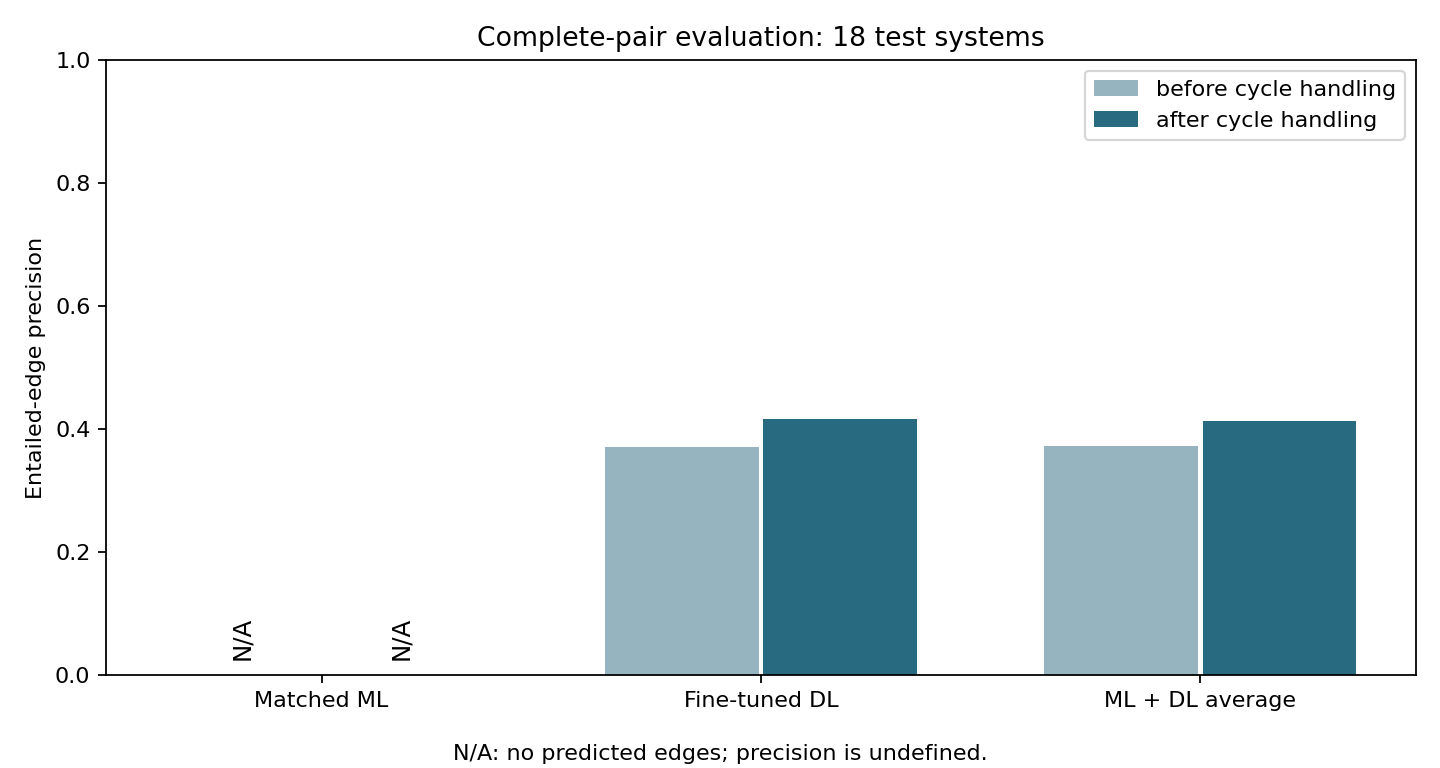

In [5]:
graphs = read("graph_metrics.json")
for name in ["Matched ML", "main", "Hybrid matched ML + DL"]:
    print(name, graphs[name]["summary"])
display(Image(filename=str(OUT / "graph_precision.png")))

## 5. Reviewed development cases

The small-system reviewer checks compatible DAGs using the premise, not test reference labels. This is automated logical review under stated assumptions, not human approval. Uncertain edges do not enter the approved graph.

In [6]:
demo = read("demo.json")
print(demo["reviewer"])
print("Integration graph source:", demo["integration_model"], demo.get("integration_note", ""))
case = demo["cases"][0]
print(case["premise"])
print(case["outcome"])
display(pd.DataFrame(case["review"])[["source", "target", "score", "status", "compatible_DAGs", "DAGs_with_edge"]])
print("Other saved cases:", [(i,c["outcome"]) for i,c in enumerate(demo["cases"]) if i])

Automated exhaustive DAG consistency audit; not a human reviewer
Integration graph source: Hybrid matched ML + DL 
Suppose there is a closed system of 4 variables, A, B, C and D. All the statistical relations among these 4 variables are as follows: A correlates with B. A correlates with C. A correlates with D. B correlates with C. B correlates with D. C correlates with D. However, B and C are independent given A.
approved edges available


,source,target,score,status,compatible_DAGs,DAGs_with_edge
0,A,D,0.398911,approved,3,3
1,B,D,0.398730,approved,3,3
2,C,D,0.399962,approved,3,3


Other saved cases: [(1, 'abstain: no approved direct edges'), (2, 'approved edges available')]


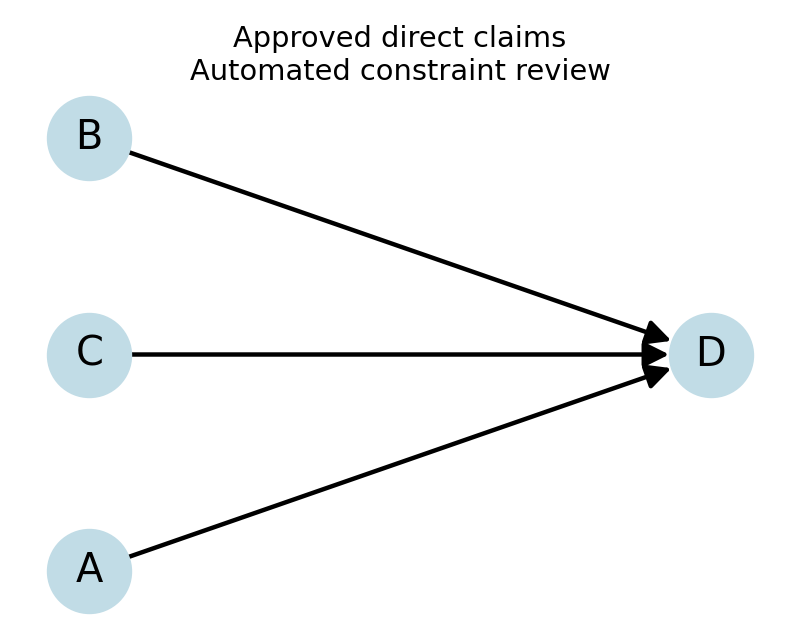

In [7]:
if (OUT / "reviewed_graph.png").exists(): display(Image(filename=str(OUT / "reviewed_graph.png")))

## 6. Observation and intervention

Re-extract the reviewed triples, rebuild their DAG, and recompute the numerical queries using supplied CPDs. The integration query is independently checked by enumeration; the separate confounded network has known answers 0.89, 0.85 and 0.25. These probabilities were not estimated from Corr2Cause.

In [8]:
replay = subprocess.run([sys.executable, str(ROOT / "scripts" / "replay_phase2_demo.py")], capture_output=True, text=True, check=True)
live = json.loads(replay.stdout)
display(pd.DataFrame(live["triples"])[["subject", "relation", "object", "confidence"]])
print("Recomputed integration:", live["integration"])
for query in live["known_queries"]: print(query)
assert live["integration"]["passed"]
assert all(q["passed"] for q in live["known_queries"])

,subject,relation,object,confidence
0,A,direct_cause,D,0.398911
1,B,direct_cause,D,0.398730
2,C,direct_cause,D,0.399962


Recomputed integration: {'cpds': {'A': {'p_high': [0.5], 'parents': []}, 'B': {'p_high': [0.5], 'parents': []}, 'C': {'p_high': [0.5], 'parents': []}, 'D': {'p_high': [0.2, 0.4, 0.4, 0.6000000000000001, 0.4, 0.6000000000000001, 0.6000000000000001, 0.8], 'parents': ['A', 'B', 'C']}}, 'cpd_source': 'Supplied demonstration assumptions, not fitted to observations', 'query': 'P(D=1 | do(A=1))', 'actual': 0.6000000000000001, 'expected_enumeration': 0.6000000000000001, 'passed': True}
{'query': 'P(Y=1 | X=1)', 'expected': 0.89, 'actual': 0.89, 'passed': True}
{'query': 'P(Y=1 | do(X=1))', 'expected': 0.85, 'actual': 0.8500000000000001, 'passed': True}
{'query': 'P(Y=1 | do(X=0))', 'expected': 0.25, 'actual': 0.25, 'passed': True}


## 7. Reproduce the offline demo

The command verifies the saved-artifact fingerprint. Training is a separate explicit command.

In [9]:
result = subprocess.run([sys.executable, str(ROOT / "phase2.py"), "demo"], capture_output=True, text=True, check=True)
print(result.stdout[:2500])

# Phase 2 results

Train subset: 2100 records in whole premise groups; dev 984; test 1162.
This is a local compute-budget experiment, not a full-205,734-row DL training run.

| Model | Dev macro F1 | Test macro F1 | Positive P | Positive R |
|---|---:|---:|---:|---:|
| Matched ML | 0.5788 | 0.5927 | 0.3431 | 0.2611 |
| Full-train ML (context only) | 0.6534 | 0.6357 | 0.3510 | 0.4778 |
| main | 0.6844 | 0.6726 | 0.3739 | 0.7333 |
| frozen | 0.5917 | 0.5679 | 0.3040 | 0.2111 |
| unweighted | 0.6510 | 0.6443 | 0.3408 | 0.6722 |
| Hybrid matched ML + DL | 0.6871 | 0.6718 | 0.3725 | 0.7389 |

Demo classifier selected on development data: Hybrid matched ML + DL.
Full-train ML is contextual only. Fair budget comparison uses Matched ML and the same DL training rows.
Graph scores measure entailed direct relations, with cycle removal evaluated separately.
Demo review uses an explicit finite-DAG constraint check on small systems; it is automated, not human approval.
CPDs in the numerical demo are

## Limits

One seed, a small training subset, synthetic language, approximate window pooling and strong review assumptions limit conclusions. A DAG alone does not prove causal truth. Full-data Phase 1 performance is context, not an equal-budget DL comparison. Team members must review the implementation and rehearse individual viva answers.